In [85]:
import soccerdata as sd
import pandas as pd
from pathlib import Path
import numpy as np

# Five leagues and five seasons
leagues = [
    "ENG-Premier League",
    "ESP-La Liga",
    "GER-Bundesliga",
    "ITA-Serie A",
    "FRA-Ligue 1"
]

seasons = [
    "2021/2022",
    "2022/2023",
    "2023/2024",
    "2024/2025",
    "2025/2026"
]

data_folder = Path("match_prediction_data")
data_folder.mkdir(exist_ok=True)

all_matches = []

for league in leagues:
    for season in seasons:
        print(f"Fetching {league} — {season}...")

        try:
            understat = sd.Understat(
                leagues=league,
                seasons=season
            )

            df = understat.read_schedule().reset_index()

            # Keep completed matches only
            df = df[df["is_result"] == True].copy()

            # Keep the season and league identifiable
            df["league_name"] = league
            df["season_label"] = season

            # Validate required columns
            required = [
                "date", "home_team", "away_team",
                "home_goals", "away_goals",
                "home_xg", "away_xg", "game_id"
            ]

            missing_columns = [
                col for col in required if col not in df.columns
            ]

            if missing_columns:
                print("Missing columns:", missing_columns)
                continue

            df = df.dropna(subset=required)

            all_matches.append(df)
            print(f"  Retrieved {len(df)} matches")

        except Exception as e:
            print(f"  FAILED: {e}")

if all_matches:
    matches_all = pd.concat(all_matches, ignore_index=True)

    output_path = data_folder / "understat_matches.csv"
    matches_all.to_csv(output_path, index=False)

    print("\nDownload summary")
    print("Total matches:", len(matches_all))
    print("Unique match IDs:", matches_all["game_id"].nunique())
    print("Leagues:", matches_all["league_name"].nunique())
    print("Seasons:", matches_all["season_label"].nunique())
    print("Saved to:", output_path.resolve())

    display(
        matches_all.groupby(
            ["league_name", "season_label"]
        ).size().unstack(fill_value=0)
    )
else:
    print("No datasets retrieved. Check the errors above.")

Fetching ENG-Premier League — 2021/2022...


[10/16/26 23:19:39] INFO     Saving cached data to C:\Users\yashr\soccerdata\data\Understat          ]8;id=15820493;file://c:\Users\yashr\AppData\Local\Programs\Python\Python312\Lib\site-packages\soccerdata\_common.py\_common.py]8;;\:]8;id=15820494;file://c:\Users\yashr\AppData\Local\Programs\Python\Python312\Lib\site-packages\soccerdata\_common.py#250\250]8;;\

  Retrieved 380 matches
Fetching ENG-Premier League — 2022/2023...


[10/16/26 23:19:40] INFO     Saving cached data to C:\Users\yashr\soccerdata\data\Understat          ]8;id=15820499;file://c:\Users\yashr\AppData\Local\Programs\Python\Python312\Lib\site-packages\soccerdata\_common.py\_common.py]8;;\:]8;id=15820500;file://c:\Users\yashr\AppData\Local\Programs\Python\Python312\Lib\site-packages\soccerdata\_common.py#250\250]8;;\

  Retrieved 380 matches
Fetching ENG-Premier League — 2023/2024...


...

[10/16/26 23:19:57] INFO     Saving cached data to C:\Users\yashr\soccerdata\data\Understat          ]8;id=15820631;file://c:\Users\yashr\AppData\Local\Programs\Python\Python312\Lib\site-packages\soccerdata\_common.py\_common.py]8;;\:]8;id=15820632;file://c:\Users\yashr\AppData\Local\Programs\Python\Python312\Lib\site-packages\soccerdata\_common.py#250\250]8;;\

  Retrieved 306 matches
Fetching FRA-Ligue 1 — 2025/2026...


[10/16/26 23:19:58] INFO     Saving cached data to C:\Users\yashr\soccerdata\data\Understat          ]8;id=15820637;file://c:\Users\yashr\AppData\Local\Programs\Python\Python312\Lib\site-packages\soccerdata\_common.py\_common.py]8;;\:]8;id=15820638;file://c:\Users\yashr\AppData\Local\Programs\Python\Python312\Lib\site-packages\soccerdata\_common.py#250\250]8;;\

  Retrieved 306 matches

Download summary
Total matches: 8908
Unique match IDs: 8908
Leagues: 5
Seasons: 5
Saved to: C:\Users\yashr\Documents\football analytics\matchprediction - PROJECT 6\match_prediction_data\understat_matches.csv


season_label,2021/2022,2022/2023,2023/2024,2024/2025,2025/2026
league_name,,,,,
ENG-Premier League,380,380,380,380,380
ESP-La Liga,380,380,380,380,380
FRA-Ligue 1,380,380,306,306,306
GER-Bundesliga,306,306,306,306,306
ITA-Serie A,380,380,380,380,380


In [86]:
matches_all["date"] = pd.to_datetime(matches_all["date"])

matches_all["outcome"] = "Draw"

matches_all.loc[
    matches_all["home_goals"] > matches_all["away_goals"],
    "outcome"
] = "Home Win"

matches_all.loc[
    matches_all["home_goals"] < matches_all["away_goals"],
    "outcome"
] = "Away Win"

display(matches_all[
    ["date", "league_name", "home_team", "away_team",
     "home_goals", "away_goals", "home_xg", "away_xg", "outcome"]
].head(10))

print("\nOutcome distribution:")
print(matches_all["outcome"].value_counts())

,date,league_name,home_team,away_team,home_goals,away_goals,home_xg,away_xg,outcome
0,2021-08-13 19:00:00,ENG-Premier League,Brentford,Arsenal,2,0,1.88818,1.02385,Home Win
1,2021-08-14 14:00:00,ENG-Premier League,Burnley,Brighton,1,2,1.79548,1.6853,Away Win
2,2021-08-14 14:00:00,ENG-Premier League,Chelsea,Crystal Palace,3,0,1.18709,0.321701,Home Win
3,2021-08-14 14:00:00,ENG-Premier League,Everton,Southampton,3,1,2.38863,0.580601,Home Win
4,2021-08-14 14:00:00,ENG-Premier League,Leicester,Wolverhampton Wanderers,1,0,0.668082,1.32714,Home Win
5,2021-08-14 11:30:00,ENG-Premier League,Manchester United,Leeds,5,1,1.64248,0.568342,Home Win
6,2021-08-14 16:30:00,ENG-Premier League,Norwich,Liverpool,0,3,1.3333,1.78728,Away Win
7,2021-08-14 14:00:00,ENG-Premier League,Watford,Aston Villa,3,2,1.35036,1.13718,Home Win
8,2021-08-15 13:00:00,ENG-Premier League,Newcastle United,West Ham,2,4,1.67926,3.00939,Away Win
9,2021-08-15 15:30:00,ENG-Premier League,Tottenham,Manchester City,1,0,1.06014,2.10585,Home Win



Outcome distribution:
outcome
Home Win    3878
Away Win    2768
Draw        2262
Name: count, dtype: int64


In [87]:
matches_features = matches_all.copy()

# Rebuild team-level historical xG features
home_history = matches_all[
    ["game_id", "date", "league_name", "season_label",
 "home_team", "home_xg", "away_xg"]
].rename(columns={
    "home_team": "team",
    "home_xg": "xg_for",
    "away_xg": "xg_against",
})

away_history = matches_all[
    ["game_id", "date", "league_name", "season_label",
 "away_team", "away_xg", "home_xg"]
].rename(columns={
    "away_team": "team",
    "away_xg": "xg_for",
    "home_xg": "xg_against",
})

team_history = pd.concat(
    [home_history, away_history],
    ignore_index=True,
).sort_values(
    ["league_name", "season_label", "team", "date"]
).reset_index(drop=True)

team_groups = ["league_name", "season_label", "team"]

team_history["avg_xg_last5"] = (
    team_history.groupby(team_groups)["xg_for"]
    .transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())
)

team_history["avg_xga_last5"] = (
    team_history.groupby(team_groups)["xg_against"]
    .transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())
)

home_form = team_history[
    ["date", "league_name", "season_label", "team",
     "avg_xg_last5", "avg_xga_last5"]
].rename(columns={
    "team": "home_team",
    "avg_xg_last5": "home_avg_xg_last5",
    "avg_xga_last5": "home_avg_xga_last5",
})

away_form = team_history[
    ["date", "league_name", "season_label", "team",
     "avg_xg_last5", "avg_xga_last5"]
].rename(columns={
    "team": "away_team",
    "avg_xg_last5": "away_avg_xg_last5",
    "avg_xga_last5": "away_avg_xga_last5",
})

# Calculate league averages by date so same-day matches
# cannot influence one another's fallback values.
daily_xg = matches_all.groupby(
    ["league_name", "season_label", "date"],
    as_index=False,
).agg(
    home_xg_sum=("home_xg", "sum"),
    home_xg_count=("home_xg", "count"),
    away_xg_sum=("away_xg", "sum"),
    away_xg_count=("away_xg", "count"),
).sort_values(
    ["league_name", "season_label", "date"]
).reset_index(drop=True)

league_groups = ["league_name", "season_label"]

for col in ["home_xg_sum", "home_xg_count", "away_xg_sum", "away_xg_count"]:
    daily_xg[f"prior_{col}"] = (
        daily_xg.groupby(league_groups)[col]
        .transform(lambda s: s.cumsum().shift(1))
    )

daily_xg["prior_league_avg_home_xg"] = (
    daily_xg["prior_home_xg_sum"] / daily_xg["prior_home_xg_count"]
)

daily_xg["prior_league_avg_away_xg"] = (
    daily_xg["prior_away_xg_sum"] / daily_xg["prior_away_xg_count"]
)

daily_prior = daily_xg[
    [
        "date", "league_name", "season_label",
        "prior_league_avg_home_xg", "prior_league_avg_away_xg",
    ]
]

# Remove the old versions before rebuilding them.
xg_columns = [
    "home_avg_xg_last5", "home_avg_xga_last5",
    "away_avg_xg_last5", "away_avg_xga_last5",
    "prior_league_avg_home_xg", "prior_league_avg_away_xg",
]

matches_features = matches_features.drop(
    columns=xg_columns,
    errors="ignore",
)

matches_features = matches_features.merge(
    home_form,
    on=["date", "league_name", "season_label", "home_team"],
    how="left",
    validate="one_to_one",
)

matches_features = matches_features.merge(
    away_form,
    on=["date", "league_name", "season_label", "away_team"],
    how="left",
    validate="one_to_one",
)

matches_features = matches_features.merge(
    daily_prior,
    on=["date", "league_name", "season_label"],
    how="left",
    validate="many_to_one",
)

# Fill missing team history with prior league averages.
matches_features["home_avg_xg_last5"] = (
    matches_features["home_avg_xg_last5"]
    .fillna(matches_features["prior_league_avg_home_xg"])
)

matches_features["home_avg_xga_last5"] = (
    matches_features["home_avg_xga_last5"]
    .fillna(matches_features["prior_league_avg_away_xg"])
)

matches_features["away_avg_xg_last5"] = (
    matches_features["away_avg_xg_last5"]
    .fillna(matches_features["prior_league_avg_away_xg"])
)

matches_features["away_avg_xga_last5"] = (
    matches_features["away_avg_xga_last5"]
    .fillna(matches_features["prior_league_avg_home_xg"])
)

# Preseason prior for the first date in each league-season.
form_columns = [
    "home_avg_xg_last5", "home_avg_xga_last5",
    "away_avg_xg_last5", "away_avg_xga_last5",
]

matches_features[form_columns] = (
    matches_features[form_columns].fillna(1.35)
)

matches_features = matches_features.sort_values(
    ["date", "league_name"]
).reset_index(drop=True)

print("Total matches:", len(matches_features))
print("Duplicate match IDs:", matches_features["game_id"].duplicated().sum())
print("\nMissing rolling xG features:")
print(matches_features[form_columns].isna().sum())

print("\nSample rows:")
display(
    matches_features[
        [
            "date", "league_name", "home_team", "away_team",
            "home_avg_xg_last5", "away_avg_xg_last5",
            "prior_league_avg_home_xg", "prior_league_avg_away_xg",
        ]
    ].head(15)
)

Total matches: 8908
Duplicate match IDs: 0

Missing rolling xG features:
home_avg_xg_last5     0
home_avg_xga_last5    0
away_avg_xg_last5     0
away_avg_xga_last5    0
dtype: int64

Sample rows:


,date,league_name,home_team,away_team,home_avg_xg_last5,away_avg_xg_last5,prior_league_avg_home_xg,prior_league_avg_away_xg
0,2021-08-06 19:00:00,FRA-Ligue 1,Monaco,Nantes,1.35,1.35,<NA>,<NA>
1,2021-08-07 15:00:00,FRA-Ligue 1,Lyon,Brest,1.76899,0.239715,1.76899,0.239715
2,2021-08-07 19:00:00,FRA-Ligue 1,Troyes,Paris Saint Germain,1.4721,0.629687,1.4721,0.629687
3,2021-08-08 11:00:00,FRA-Ligue 1,Rennes,Lens,1.187458,0.915295,1.187458,0.915295
4,2021-08-08 13:00:00,FRA-Ligue 1,Bordeaux,Clermont Foot,1.040199,1.220564,1.040199,1.220564
5,2021-08-08 13:00:00,FRA-Ligue 1,Nice,Reims,1.040199,1.220564,1.040199,1.220564
6,2021-08-08 13:00:00,FRA-Ligue 1,Saint-Etienne,Lorient,1.040199,1.220564,1.040199,1.220564
7,2021-08-08 13:00:00,FRA-Ligue 1,Strasbourg,Angers,1.040199,1.220564,1.040199,1.220564
8,2021-08-08 15:00:00,FRA-Ligue 1,Metz,Lille,0.986974,1.281171,0.986974,1.281171
9,2021-08-08 18:45:00,FRA-Ligue 1,Montpellier,Marseille,0.990712,1.319091,0.990712,1.319091


In [88]:
missing_counts = matches_features.isna().sum()

print("Columns with missing values:")
print(missing_counts[missing_counts > 0])

print("\nTotal missing cells:", matches_features.isna().sum().sum())
print("Total rows:", len(matches_features))

Columns with missing values:
prior_league_avg_home_xg    33
prior_league_avg_away_xg    33
dtype: int64

Total missing cells: 66
Total rows: 8908


In [89]:
print("Missing values in model features:")
print(matches_features[form_columns].isna().sum())

print("\nMissing target labels:", matches_features["outcome"].isna().sum())
print("Total matches:", len(matches_features))
print("Duplicate game IDs:", matches_features["game_id"].duplicated().sum())

assert matches_features[form_columns].notna().all().all()
assert matches_features["outcome"].notna().all()
assert matches_features["game_id"].is_unique

print("\nAll validation checks passed.")

Missing values in model features:
home_avg_xg_last5     0
home_avg_xga_last5    0
away_avg_xg_last5     0
away_avg_xga_last5    0
dtype: int64

Missing target labels: 0
Total matches: 8908
Duplicate game IDs: 0

All validation checks passed.


In [90]:
from collections import defaultdict

K_FACTOR = 20
HOME_ADVANTAGE_ELO = 60
INITIAL_ELO = 1500

matches_features = matches_features.sort_values(
    ["date", "league_name"]
).reset_index(drop=True)

elo_ratings = defaultdict(lambda: INITIAL_ELO)

home_elo_before = []
away_elo_before = []

for date, daily_matches in matches_features.groupby("date", sort=True):

    # Record every match's pre-match ratings first
    daily_results = []

    for idx, match in daily_matches.iterrows():
        league = match["league_name"]
        home = match["home_team"]
        away = match["away_team"]

        home_key = (league, home)
        away_key = (league, away)

        home_rating = elo_ratings[home_key]
        away_rating = elo_ratings[away_key]

        home_elo_before.append((idx, home_rating))
        away_elo_before.append((idx, away_rating))

        if match["home_goals"] > match["away_goals"]:
            actual_home = 1.0
        elif match["home_goals"] == match["away_goals"]:
            actual_home = 0.5
        else:
            actual_home = 0.0

        expected_home = 1 / (
            1 + 10 ** (
                (away_rating - (home_rating + HOME_ADVANTAGE_ELO)) / 400
            )
        )

        change = K_FACTOR * (actual_home - expected_home)

        daily_results.append((home_key, away_key, change))

    # Update ratings only after every match on this date is recorded
    for home_key, away_key, change in daily_results:
        elo_ratings[home_key] += change
        elo_ratings[away_key] -= change

# Put ratings back in their correct match rows
home_elo_map = dict(home_elo_before)
away_elo_map = dict(away_elo_before)

matches_features["home_elo"] = matches_features.index.map(home_elo_map)
matches_features["away_elo"] = matches_features.index.map(away_elo_map)

matches_features["elo_difference"] = (
    matches_features["home_elo"] - matches_features["away_elo"]
)

display(
    matches_features[
        [
            "date", "league_name", "home_team", "away_team",
            "home_elo", "away_elo", "elo_difference", "outcome"
        ]
    ].head(10)
)

print("Missing home Elo:", matches_features["home_elo"].isna().sum())
print("Missing away Elo:", matches_features["away_elo"].isna().sum())
print("Total matches:", len(matches_features))

,date,league_name,home_team,away_team,home_elo,away_elo,elo_difference,outcome
0,2021-08-06 19:00:00,FRA-Ligue 1,Monaco,Nantes,1500.0,1500.0,0.0,Draw
1,2021-08-07 15:00:00,FRA-Ligue 1,Lyon,Brest,1500.0,1500.0,0.0,Draw
2,2021-08-07 19:00:00,FRA-Ligue 1,Troyes,Paris Saint Germain,1500.0,1500.0,0.0,Away Win
3,2021-08-08 11:00:00,FRA-Ligue 1,Rennes,Lens,1500.0,1500.0,0.0,Draw
4,2021-08-08 13:00:00,FRA-Ligue 1,Bordeaux,Clermont Foot,1500.0,1500.0,0.0,Away Win
5,2021-08-08 13:00:00,FRA-Ligue 1,Nice,Reims,1500.0,1500.0,0.0,Draw
6,2021-08-08 13:00:00,FRA-Ligue 1,Saint-Etienne,Lorient,1500.0,1500.0,0.0,Draw
7,2021-08-08 13:00:00,FRA-Ligue 1,Strasbourg,Angers,1500.0,1500.0,0.0,Away Win
8,2021-08-08 15:00:00,FRA-Ligue 1,Metz,Lille,1500.0,1500.0,0.0,Draw
9,2021-08-08 18:45:00,FRA-Ligue 1,Montpellier,Marseille,1500.0,1500.0,0.0,Away Win


Missing home Elo: 0
Missing away Elo: 0
Total matches: 8908


In [91]:
matches_features = matches_features.sort_values(
    ["league_name", "season_label", "date"]
).reset_index(drop=True)

home_last_match = {}
away_last_match = {}

home_rest_days = []
away_rest_days = []

for _, match in matches_features.iterrows():
    date = match["date"]
    league = match["league_name"]
    season = match["season_label"]
    home = match["home_team"]
    away = match["away_team"]

    home_key = (league, season, home)
    away_key = (league, season, away)

    home_rest = (
        (date - home_last_match[home_key]).days
        if home_key in home_last_match else 7
    )

    away_rest = (
        (date - away_last_match[away_key]).days
        if away_key in away_last_match else 7
    )

    home_rest_days.append(home_rest)
    away_rest_days.append(away_rest)

    home_last_match[home_key] = date
    away_last_match[away_key] = date

matches_features["home_rest_days"] = home_rest_days
matches_features["away_rest_days"] = away_rest_days

matches_features["rest_days_difference"] = (
    matches_features["home_rest_days"]
    - matches_features["away_rest_days"]
)

print("Maximum home rest:", matches_features["home_rest_days"].max())
print("Maximum away rest:", matches_features["away_rest_days"].max())
print("Minimum home rest:", matches_features["home_rest_days"].min())
print("Minimum away rest:", matches_features["away_rest_days"].min())

Maximum home rest: 79
Maximum away rest: 78
Minimum home rest: 2
Minimum away rest: 2


In [92]:
import numpy as np
import pandas as pd

form_data = matches_features.copy().reset_index(drop=True)
form_data["_match_id"] = np.arange(len(form_data))

# Create one row per team appearance
home_history = pd.DataFrame({
    "_match_id": form_data["_match_id"],
    "date": form_data["date"],
    "league_name": form_data["league_name"],
    "season_label": form_data["season_label"],
    "team": form_data["home_team"],
    "points": np.select(
        [
            form_data["home_goals"] > form_data["away_goals"],
            form_data["home_goals"] == form_data["away_goals"]
        ],
        [3, 1],
        default=0
    ),
    "goal_difference": (
        form_data["home_goals"] - form_data["away_goals"]
    ),
    "side": "home"
})

away_history = pd.DataFrame({
    "_match_id": form_data["_match_id"],
    "date": form_data["date"],
    "league_name": form_data["league_name"],
    "season_label": form_data["season_label"],
    "team": form_data["away_team"],
    "points": np.select(
        [
            form_data["away_goals"] > form_data["home_goals"],
            form_data["away_goals"] == form_data["home_goals"]
        ],
        [3, 1],
        default=0
    ),
    "goal_difference": (
        form_data["away_goals"] - form_data["home_goals"]
    ),
    "side": "away"
})

team_history = pd.concat(
    [home_history, away_history],
    ignore_index=True
).sort_values(
    ["league_name", "season_label", "team", "date", "_match_id"]
).reset_index(drop=True)

group_keys = ["league_name", "season_label", "team"]

# Shift first so the current match cannot enter its own features
team_history["points_last5"] = (
    team_history.groupby(group_keys)["points"]
    .transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())
    .fillna(1.0)
)

team_history["goal_difference_last5"] = (
    team_history.groupby(group_keys)["goal_difference"]
    .transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())
    .fillna(0.0)
)

# Split home and away features by their unique match IDs
home_form = (
    team_history[team_history["side"] == "home"]
    .set_index("_match_id")
)

away_form = (
    team_history[team_history["side"] == "away"]
    .set_index("_match_id")
)

form_data["home_points_per_game_last5"] = (
    home_form.loc[form_data["_match_id"], "points_last5"].to_numpy()
)
form_data["home_goal_difference_last5"] = (
    home_form.loc[
        form_data["_match_id"], "goal_difference_last5"
    ].to_numpy()
)
form_data["away_points_per_game_last5"] = (
    away_form.loc[form_data["_match_id"], "points_last5"].to_numpy()
)
form_data["away_goal_difference_last5"] = (
    away_form.loc[
        form_data["_match_id"], "goal_difference_last5"
    ].to_numpy()
)

new_features = [
    "home_points_per_game_last5",
    "away_points_per_game_last5",
    "home_goal_difference_last5",
    "away_goal_difference_last5"
]

# Integrity checks
assert len(form_data) == len(matches_features)
assert form_data["game_id"].is_unique
assert form_data[new_features].notna().all().all()

print("Rolling form features created successfully.")
print("Rows:", len(form_data))
print("Unique matches:", form_data["game_id"].nunique())
print("Missing new features:", form_data[new_features].isna().sum().sum())
display(form_data[new_features].describe().round(3))

Rolling form features created successfully.
Rows: 8908
Unique matches: 8908
Missing new features: 0


,home_points_per_game_last5,away_points_per_game_last5,home_goal_difference_last5,away_goal_difference_last5
count,8908.000,8908.000,8908.000,8908.000
mean,1.340,1.385,-0.034,0.035
std,0.716,0.721,1.025,1.030
min,0.000,0.000,-6.000,-5.000
25%,0.800,0.800,-0.667,-0.600
50%,1.200,1.400,0.000,0.000
75%,1.800,2.000,0.600,0.600
max,3.000,3.000,5.000,6.000


In [93]:
model_features = [
    "home_avg_xg_last5",
    "home_avg_xga_last5",
    "away_avg_xg_last5",
    "away_avg_xga_last5",
    "home_elo",
    "away_elo",
    "elo_difference",
    "home_rest_days",
    "away_rest_days",
    "rest_days_difference",
    "home_points_per_game_last5",
    "away_points_per_game_last5",
    "home_goal_difference_last5",
    "away_goal_difference_last5"
]

target = "outcome"

train_data = form_data[
    form_data["season_label"].isin([
        "2021/2022", "2022/2023", "2023/2024"
    ])
].copy()

validation_data = form_data[
    form_data["season_label"] == "2024/2025"
].copy()

test_data = form_data[
    form_data["season_label"] == "2025/2026"
].copy()

X_train = train_data[model_features]
y_train = train_data[target]

X_val = validation_data[model_features]
y_val = validation_data[target]

X_test = test_data[model_features]
y_test = test_data[target]

# Integrity checks
assert len(train_data) == 5404
assert len(validation_data) == 1752
assert len(test_data) == 1752

assert X_train.notna().all().all()
assert X_val.notna().all().all()
assert X_test.notna().all().all()

assert list(X_train.columns) == model_features

print("Feature update successful.")
print("Number of features:", len(model_features))
print("Training matches:", len(X_train))
print("Validation matches:", len(X_val))
print("Test matches:", len(X_test))
print("Missing feature values:", X_train.isna().sum().sum()
      + X_val.isna().sum().sum()
      + X_test.isna().sum().sum())

Feature update successful.
Number of features: 14
Training matches: 5404
Validation matches: 1752
Test matches: 1752
Missing feature values: 0


In [105]:
from sklearn.metrics import accuracy_score, f1_score
from sklearn.dummy import DummyClassifier

X_train = train_data[model_features]
y_train = train_data[target]

X_val = validation_data[model_features]
y_val = validation_data[target]

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)

baseline_predictions = baseline.predict(X_val)

print("Baseline model: Most Frequent Outcome")
print("Predicted outcome:", baseline.classes_[baseline.class_prior_.argmax()])
print("Validation accuracy:", round(accuracy_score(y_val, baseline_predictions), 4))
print(
    "Validation macro F1:",
    round(f1_score(y_val, baseline_predictions, average="macro"), 4)
)

Baseline model: Most Frequent Outcome
Predicted outcome: Home Win
Validation accuracy: 0.4201
Validation macro F1: 0.1972


In [95]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, log_loss, classification_report
import pandas as pd

class_weight_options = [
    {"Away Win": 1, "Draw": 1, "Home Win": 1},
    {"Away Win": 1, "Draw": 1.5, "Home Win": 1},
    {"Away Win": 1, "Draw": 2, "Home Win": 1},
    {"Away Win": 1, "Draw": 3, "Home Win": 1},
]

weight_results = []
weight_models = {}

for weights in class_weight_options:
    model = RandomForestClassifier(
        n_estimators=300,
        max_depth=12,
        min_samples_leaf=10,
        class_weight=weights,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train, y_train)
    predictions = model.predict(X_val)
    probabilities = model.predict_proba(X_val)

    weight_models[weights["Draw"]] = model

    report = classification_report(
        y_val,
        predictions,
        labels=["Away Win", "Draw", "Home Win"],
        output_dict=True,
        zero_division=0
    )

    weight_results.append({
        "Draw Weight": weights["Draw"],
        "Accuracy": accuracy_score(y_val, predictions),
        "Macro F1": f1_score(y_val, predictions, average="macro"),
        "Log Loss": log_loss(
            y_val, probabilities,
            labels=model.classes_
        ),
        "Draw Precision": report["Draw"]["precision"],
        "Draw Recall": report["Draw"]["recall"],
        "Draw F1": report["Draw"]["f1-score"]
    })

display(pd.DataFrame(weight_results).round(4))

,Draw Weight,Accuracy,Macro F1,Log Loss,Draw Precision,Draw Recall,Draw F1
0,1.0,0.5257,0.4079,0.9979,0.3913,0.0205,0.0390
1,1.5,0.5148,0.4467,1.0054,0.2932,0.1279,0.1781
2,2.0,0.4852,0.4598,1.0198,0.2688,0.2945,0.2810
3,3.0,0.4275,0.4198,1.0527,0.2626,0.5342,0.3521


,Predicted Away Win,Predicted Draw,Predicted Home Win
Actual Away Win,268,173,137
Actual Draw,121,129,188
Actual Home Win,105,178,453


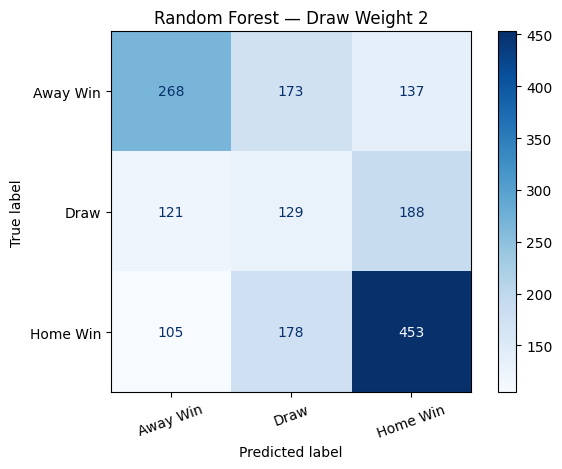

In [107]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

selected_rf = weight_models[2.0]
predictions_weight2 = selected_rf.predict(X_val)

labels = ["Away Win", "Draw", "Home Win"]

cm = confusion_matrix(
    y_val,
    predictions_weight2,
    labels=labels
)

display(pd.DataFrame(
    cm,
    index=[f"Actual {label}" for label in labels],
    columns=[f"Predicted {label}" for label in labels]
))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
).plot(cmap="Blues", values_format="d")

plt.title("Random Forest — Draw Weight 2")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [106]:
import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, log_loss

from xgboost import XGBClassifier

# Use the complete feature dataframe
data = form_data.copy()

features = model_features
target_col = "outcome"

# Confirm the expected data is present
required = features + [target_col, "season_label", "date"]
missing = [c for c in required if c not in data.columns]

assert not missing, f"Missing columns: {missing}"
assert len(features) == 14
assert data[required].notna().all().all()

# Expanding-window validation folds
folds = [
    {
        "train_seasons": ["2021/2022", "2022/2023"],
        "validation_season": "2023/2024",
    },
    {
        "train_seasons": ["2021/2022", "2022/2023", "2023/2024"],
        "validation_season": "2024/2025",
    },
]

results = []

for fold_number, fold in enumerate(folds, start=1):
    train = data[
        data["season_label"].isin(fold["train_seasons"])
    ].copy()

    val = data[
        data["season_label"] == fold["validation_season"]
    ].copy()

    assert len(train) > 0 and len(val) > 0
    assert train["date"].max() < val["date"].min()

    X_train = train[features]
    y_train = train[target_col]
    X_val = val[features]
    y_val = val[target_col]

    # Logistic Regression
    logistic = Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=2000)),
    ])

    # Random Forest with the previously tested draw weight
    rf_draw2 = RandomForestClassifier(
        n_estimators=300,
        max_depth=12,
        min_samples_leaf=10,
        class_weight={
            "Away Win": 1,
            "Draw": 2,
            "Home Win": 1,
        },
        random_state=42,
        n_jobs=-1,
    )

    # Standard balanced Random Forest for comparison
    rf_balanced = RandomForestClassifier(
        n_estimators=300,
        max_depth=12,
        min_samples_leaf=10,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1,
    )

    # Encode labels for XGBoost
    encoder = LabelEncoder()
    y_train_encoded = encoder.fit_transform(y_train)
    y_val_encoded = encoder.transform(y_val)

    xgb = XGBClassifier(
        objective="multi:softprob",
        num_class=len(encoder.classes_),
        n_estimators=400,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        min_child_weight=5,
        reg_lambda=2,
        eval_metric="mlogloss",
        random_state=42,
        n_jobs=-1,
    )

    candidates = [
        ("Logistic Regression", logistic, False),
        ("Random Forest (balanced)", rf_balanced, False),
        ("Random Forest (draw weight 2)", rf_draw2, False),
        ("XGBoost", xgb, True),
    ]

    for name, model, use_encoded_labels in candidates:
        if use_encoded_labels:
            model.fit(X_train, y_train_encoded)
            probabilities = model.predict_proba(X_val)
            predicted = encoder.inverse_transform(
                model.predict(X_val).astype(int)
            )
            loss = log_loss(
                y_val_encoded,
                probabilities,
                labels=np.arange(len(encoder.classes_)),
            )
        else:
            model.fit(X_train, y_train)
            probabilities = model.predict_proba(X_val)
            predicted = model.predict(X_val)
            loss = log_loss(
                y_val,
                probabilities,
                labels=model.classes_,
            )

        results.append({
            "Fold": fold_number,
            "Validation season": fold["validation_season"],
            "Model": name,
            "Training matches": len(train),
            "Validation matches": len(val),
            "Accuracy": accuracy_score(y_val, predicted),
            "Macro F1": f1_score(
                y_val, predicted, average="macro", zero_division=0
            ),
            "Log Loss": loss,
        })

results_df = pd.DataFrame(results)

print("WALK-FORWARD VALIDATION RESULTS")
display(
    results_df.sort_values(["Fold", "Macro F1"], ascending=[True, False])
    .round(4)
)

summary = (
    results_df.groupby("Model", as_index=False)
    .agg({
        "Accuracy": "mean",
        "Macro F1": "mean",
        "Log Loss": "mean",
    })
    .sort_values("Macro F1", ascending=False)
)

print("AVERAGE PERFORMANCE ACROSS BOTH FOLDS")
display(summary.round(4))

print(
    "The 2025/2026 final test season has not been evaluated."
)


WALK-FORWARD VALIDATION RESULTS


,Fold,Validation season,Model,Training matches,Validation matches,Accuracy,Macro F1,Log Loss
2,1,2023/2024,Random Forest (draw weight 2),3652,1752,0.5154,0.4776,0.9996
1,1,2023/2024,Random Forest (balanced),3652,1752,0.5240,0.4635,0.9969
3,1,2023/2024,XGBoost,3652,1752,0.5034,0.4213,1.0341
0,1,2023/2024,Logistic Regression,3652,1752,0.5360,0.4141,0.9802
5,2,2024/2025,Random Forest (balanced),5404,1752,0.5154,0.4601,1.0035
6,2,2024/2025,Random Forest (draw weight 2),5404,1752,0.4852,0.4598,1.0198
7,2,2024/2025,XGBoost,5404,1752,0.5131,0.4219,1.0227
4,2,2024/2025,Logistic Regression,5404,1752,0.5303,0.4028,0.9941


AVERAGE PERFORMANCE ACROSS BOTH FOLDS


,Model,Accuracy,Macro F1,Log Loss
2,Random Forest (draw weight 2),0.5003,0.4687,1.0097
1,Random Forest (balanced),0.5197,0.4618,1.0002
3,XGBoost,0.5083,0.4216,1.0284
0,Logistic Regression,0.5331,0.4085,0.9871


The 2025/2026 final test season has not been evaluated.


In [108]:
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    log_loss,
    classification_report,
    confusion_matrix,
)

# 1. Prepare training and final test datasets
final_train = form_data[
    form_data["season_label"].isin([
        "2021/2022",
        "2022/2023",
        "2023/2024",
        "2024/2025",
    ])
].copy()

final_test = form_data[
    form_data["season_label"] == "2025/2026"
].copy()

X_final_train = final_train[model_features]
y_final_train = final_train["outcome"]

X_final_test = final_test[model_features]
y_final_test = final_test["outcome"]

# 2. Integrity checks
assert len(final_train) == 7156, f"Unexpected training size: {len(final_train)}"
assert len(final_test) == 1752, f"Unexpected test size: {len(final_test)}"
assert final_train["date"].max() < final_test["date"].min()
assert X_final_train.notna().all().all()
assert X_final_test.notna().all().all()

# 3. Lock the selected model configuration
final_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=12,
    min_samples_leaf=10,
    class_weight={
        "Away Win": 1,
        "Draw": 2,
        "Home Win": 1,
    },
    random_state=42,
    n_jobs=-1,
)

# 4. Train on all pre-test seasons
final_model.fit(X_final_train, y_final_train)

# 5. Evaluate on the untouched 2025/2026 test season
test_predictions = final_model.predict(X_final_test)
test_probabilities = final_model.predict_proba(X_final_test)

print("=" * 55)
print("FINAL TEST RESULTS — 2025/2026")
print("=" * 55)

print("Training matches:", len(X_final_train))
print("Test matches:", len(X_final_test))
print("Accuracy:", round(
    accuracy_score(y_final_test, test_predictions), 4
))
print("Macro F1:", round(
    f1_score(
        y_final_test, test_predictions,
        average="macro", zero_division=0
    ), 4
))
print("Log loss:", round(
    log_loss(
        y_final_test,
        test_probabilities,
        labels=final_model.classes_,
    ), 4
))

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_final_test,
    test_predictions,
    labels=final_model.classes_,
    zero_division=0,
))

print("CONFUSION MATRIX")
print("Class order:", list(final_model.classes_))
print(confusion_matrix(
    y_final_test,
    test_predictions,
    labels=final_model.classes_,
))



FINAL TEST RESULTS — 2025/2026
Training matches: 7156
Test matches: 1752
Accuracy: 0.4755
Macro F1: 0.4546
Log loss: 1.024

CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Away Win       0.50      0.46      0.48       535
        Draw       0.29      0.33      0.31       446
    Home Win       0.58      0.57      0.57       771

    accuracy                           0.48      1752
   macro avg       0.46      0.45      0.45      1752
weighted avg       0.48      0.48      0.48      1752

CONFUSION MATRIX
Class order: ['Away Win', 'Draw', 'Home Win']
[[248 136 151]
 [129 145 172]
 [117 214 440]]


In [99]:
print("Home rest days:")
print(matches_features["home_rest_days"].describe())

print("\nAway rest days:")
print(matches_features["away_rest_days"].describe())

print("\nHome rest days below zero:",
      (matches_features["home_rest_days"] < 0).sum())

print("Away rest days below zero:",
      (matches_features["away_rest_days"] < 0).sum())

Home rest days:
count    8908.000000
mean       14.883363
std         7.927310
min         2.000000
25%        10.000000
50%        14.000000
75%        20.000000
max        79.000000
Name: home_rest_days, dtype: float64

Away rest days:
count    8908.000000
mean       14.899978
std         7.907429
min         2.000000
25%        10.000000
50%        14.000000
75%        20.000000
max        78.000000
Name: away_rest_days, dtype: float64

Home rest days below zero: 0
Away rest days below zero: 0


In [104]:
print("Training outcomes (%):")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nValidation outcomes (%):")
print((y_val.value_counts(normalize=True) * 100).round(2))

print("\nTest outcomes (%):")
print((y_test.value_counts(normalize=True) * 100).round(2))

Training outcomes (%):
outcome
Home Win    43.87
Away Win    30.63
Draw        25.50
Name: proportion, dtype: float64

Validation outcomes (%):
outcome
Home Win    42.01
Away Win    32.99
Draw        25.00
Name: proportion, dtype: float64

Test outcomes (%):
outcome
Home Win    44.01
Away Win    30.54
Draw        25.46
Name: proportion, dtype: float64


In [109]:

import pandas as pd

feature_importance = pd.DataFrame({
    "Feature": model_features,
    "Importance": final_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    "Importance", ascending=False
).reset_index(drop=True)

display(feature_importance.round(4))


,Feature,Importance
0,elo_difference,0.1571
1,home_elo,0.1130
2,away_elo,0.1045
3,home_avg_xg_last5,0.1007
4,away_avg_xg_last5,0.0863
5,away_avg_xga_last5,0.0787
6,home_avg_xga_last5,0.0712
7,home_goal_difference_last5,0.0489
8,away_goal_difference_last5,0.0454
9,home_rest_days,0.0405


In [115]:
features_with_elo = [
    "home_avg_xg_last5",
    "home_avg_xga_last5",
    "away_avg_xg_last5",
    "away_avg_xga_last5",
    "home_elo",
    "away_elo",
    "elo_difference",
    "home_rest_days",
    "away_rest_days",
    "rest_days_difference",
    "home_points_per_game_last5",
    "away_points_per_game_last5",
    "home_goal_difference_last5",
    "away_goal_difference_last5"
]

features_without_elo = [
    col for col in features_with_elo
    if col not in ["home_elo", "away_elo", "elo_difference"]
]

elo_train = train_data.copy()
elo_val = validation_data.copy()

# Verify the split before training
print("Training matches:", len(elo_train))
print("Validation matches:", len(elo_val))
print(
    "Overlapping matches:",
    elo_val["game_id"].isin(elo_train["game_id"]).sum()
)

assert elo_val["game_id"].isin(elo_train["game_id"]).sum() == 0, \
    "ERROR: Training and validation matches overlap!"

# Model with Elo
model_with_elo = RandomForestClassifier(
    n_estimators=300,
    max_depth=12,
    min_samples_leaf=10,
    class_weight={"Away Win": 1, "Draw": 2, "Home Win": 1},
    random_state=42,
    n_jobs=-1
)

model_with_elo.fit(elo_train[features_with_elo], elo_train["outcome"])
pred_with_elo = model_with_elo.predict(elo_val[features_with_elo])

# Model without Elo
model_without_elo = RandomForestClassifier(
    n_estimators=300,
    max_depth=12,
    min_samples_leaf=10,
    class_weight={"Away Win": 1, "Draw": 2, "Home Win": 1},
    random_state=42,
    n_jobs=-1
)

model_without_elo.fit(elo_train[features_without_elo], elo_train["outcome"])
pred_without_elo = model_without_elo.predict(elo_val[features_without_elo])

print("\nWITH ELO")
print("Accuracy:", round(accuracy_score(elo_val["outcome"], pred_with_elo), 4))
print("Macro F1:", round(f1_score(elo_val["outcome"], pred_with_elo, average="macro"), 4))

print("\nWITHOUT ELO")
print("Accuracy:", round(accuracy_score(elo_val["outcome"], pred_without_elo), 4))
print("Macro F1:", round(f1_score(elo_val["outcome"], pred_without_elo, average="macro"), 4))

Training matches: 5404
Validation matches: 1752
Overlapping matches: 0

WITH ELO
Accuracy: 0.4852
Macro F1: 0.4598

WITHOUT ELO
Accuracy: 0.4167
Macro F1: 0.3939


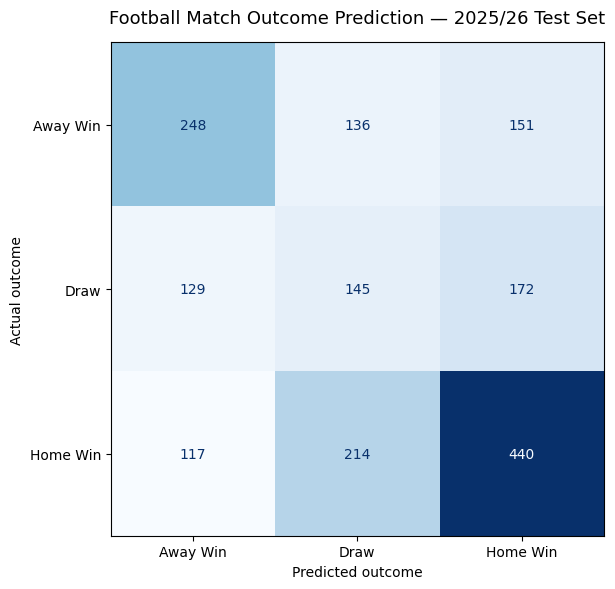

In [123]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

labels = ["Away Win", "Draw", "Home Win"]

test_predictions = final_model.predict(X_final_test)

cm = confusion_matrix(
    y_final_test,
    test_predictions,
    labels=labels
)

fig, ax = plt.subplots(figsize=(8, 6))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
).plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

ax.set_title(
    "Football Match Outcome Prediction — 2025/26 Test Set",
    fontsize=13,
    pad=14
)
ax.set_xlabel("Predicted outcome")
ax.set_ylabel("Actual outcome")

plt.tight_layout()
plt.savefig(data_folder / "confusion_matrix_2025_26.png", dpi=300, bbox_inches="tight")
plt.show()

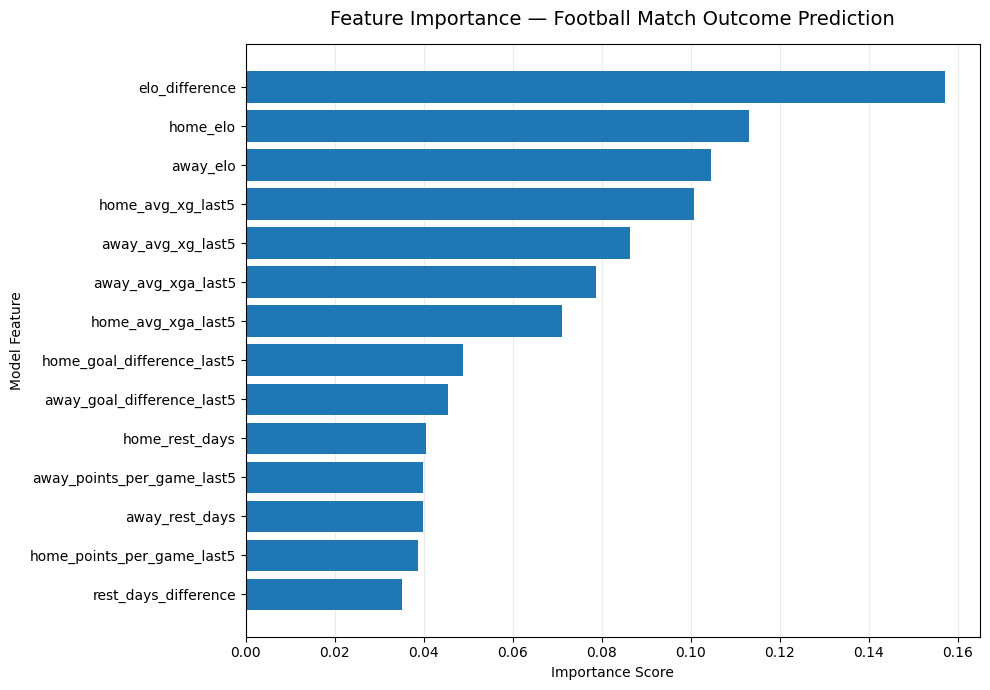

In [124]:

import pandas as pd
import matplotlib.pyplot as plt

feature_importance = pd.DataFrame({
    "Feature": model_features,
    "Importance": final_model.feature_importances_
}).sort_values("Importance", ascending=True)

fig, ax = plt.subplots(figsize=(10, 7))

ax.barh(
    feature_importance["Feature"],
    feature_importance["Importance"],
)

ax.set_title(
    "Feature Importance — Football Match Outcome Prediction",
    fontsize=14,
    pad=14
)
ax.set_xlabel("Importance Score")
ax.set_ylabel("Model Feature")

ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)


plt.tight_layout()
plt.savefig(data_folder / "feature_importance.png", dpi=300, bbox_inches="tight")
plt.show()


In [125]:
for filename in [
    "understat_matches.csv",
    "confusion_matrix_2025_26.png",
    "feature_importance.png",
]:
    path = data_folder / filename
    print(f"{filename}: {'FOUND' if path.exists() else 'MISSING'}")

understat_matches.csv: FOUND
confusion_matrix_2025_26.png: FOUND
feature_importance.png: FOUND
